In [106]:
import pandas as pd
import numpy as np

In [108]:
df = pd.read_csv('diabetes.csv', encoding='utf-8') 
df2 = pd.read_csv('isim_listesi1.csv', encoding='utf-8') 

In [110]:
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


In [112]:
df2

,ID,Ad,Soyad
0,0,Buse,Kaya
1,1,Gamze,Yılmaz
2,2,Sema,Şahin
3,3,Duygu,Demir
4,4,Zeynep,Çelik
5,5,Sema,Yıldız
6,6,Ceren,Öztürk
7,7,Elif,Doğan
8,8,Gamze,Aslan
9,9,Sema,Kara


In [114]:
nan_exists_all = df.isna().any()

print(nan_exists_all)

Pregnancies                 False
Glucose                     False
BloodPressure               False
SkinThickness               False
Insulin                     False
BMI                         False
DiabetesPedigreeFunction    False
Age                         False
Outcome                     False
dtype: bool


In [116]:
doluluk_orani = df.notna().mean() * 100
doluluk_orani

Pregnancies                 100.0
Glucose                     100.0
BloodPressure               100.0
SkinThickness               100.0
Insulin                     100.0
BMI                         100.0
DiabetesPedigreeFunction    100.0
Age                         100.0
Outcome                     100.0
dtype: float64

In [118]:
df = pd.read_csv('diabetes.csv')

hedef_sutunlar = ['Glucose', 'BloodPressure', 'Insulin']
nan_yuzdesi = 0.03 


df_hedef = df[hedef_sutunlar]
toplam_hedef_hucre = df_hedef.size
nan_sayisi = int(toplam_hedef_hucre * nan_yuzdesi)

np.random.seed(42) 

tum_indeksler = df_hedef.stack().index

nan_pozisyonlari = np.random.choice(len(tum_indeksler), nan_sayisi, replace=False)

for satir, sutun in [tum_indeksler[i] for i in nan_pozisyonlari]:
    df.loc[satir, sutun] = np.nan
output_filename = 'diabetes_secili_random_nan.csv'
df.to_csv(output_filename, index=False)


In [120]:
nan_exists_all = df.isna().any()

print(nan_exists_all)

Pregnancies                 False
Glucose                      True
BloodPressure                True
SkinThickness               False
Insulin                      True
BMI                         False
DiabetesPedigreeFunction    False
Age                         False
Outcome                     False
dtype: bool


In [122]:
print(f"Sadece {hedef_sutunlar} sütunlarında toplam {nan_sayisi} adet eksik veri eklendi.")
print(f"Yeni DataFrame, {output_filename} adıyla kaydedildi.")
print(df.isna().sum())

Sadece ['Glucose', 'BloodPressure', 'Insulin'] sütunlarında toplam 69 adet eksik veri eklendi.
Yeni DataFrame, diabetes_secili_random_nan.csv adıyla kaydedildi.
Pregnancies                  0
Glucose                     25
BloodPressure               19
SkinThickness                0
Insulin                     25
BMI                          0
DiabetesPedigreeFunction     0
Age                          0
Outcome                      0
dtype: int64


In [124]:
doluluk_orani = df.notna().mean() * 100
doluluk_orani

Pregnancies                 100.000000
Glucose                      96.744792
BloodPressure                97.526042
SkinThickness               100.000000
Insulin                      96.744792
BMI                         100.000000
DiabetesPedigreeFunction    100.000000
Age                         100.000000
Outcome                     100.000000
dtype: float64

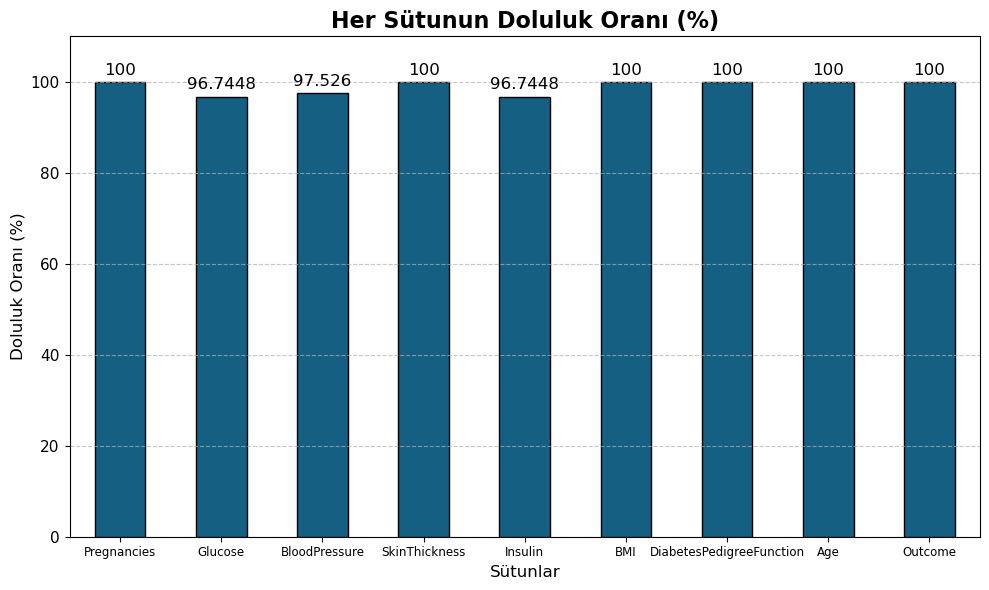

In [126]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))

ax = doluluk_orani.plot(kind='bar', color='#156082', edgecolor='black')

plt.title('Her Sütunun Doluluk Oranı (%)', fontsize=16, fontweight='bold')
plt.ylabel('Doluluk Oranı (%)', fontsize=12)
plt.xlabel('Sütunlar', fontsize=12)


plt.xticks(rotation=0, fontsize=8.5)
plt.yticks(fontsize=11)

plt.grid(axis='y', linestyle='--', alpha=0.7)

for i in ax.containers:
    ax.bar_label(i, label_type='edge', padding=3, fontsize=12)
     
plt.ylim(0, doluluk_orani.max() * 1.1)
plt.tight_layout()
plt.show()

In [128]:
 doluluk_sayisi = df.notna().sum()
 doluluk_sayisi

Pregnancies                 768
Glucose                     743
BloodPressure               749
SkinThickness               768
Insulin                     743
BMI                         768
DiabetesPedigreeFunction    768
Age                         768
Outcome                     768
dtype: int64

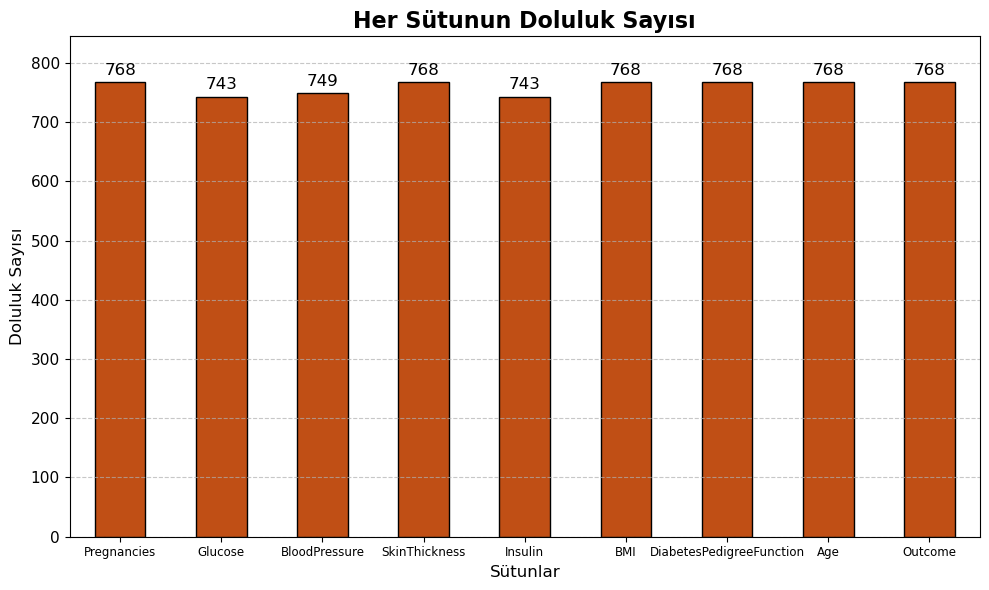

In [130]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))

ax = doluluk_sayisi.plot(kind='bar', color='#C04F15', edgecolor='black')

plt.title('Her Sütunun Doluluk Sayısı', fontsize=16, fontweight='bold')
plt.ylabel('Doluluk Sayısı', fontsize=12)
plt.xlabel('Sütunlar', fontsize=12)

plt.xticks(rotation=0, fontsize=8.5)
plt.yticks(fontsize=11)

plt.grid(axis='y', linestyle='--', alpha=0.7)

for i in ax.containers:
    ax.bar_label(i, label_type='edge', padding=3, fontsize=12)
    
plt.ylim(0, doluluk_sayisi.max() * 1.1)
plt.tight_layout()
plt.show()

In [132]:
df['Glucose'].mean()

120.76985195154778

In [150]:
df['Glucose'].fillna(df['Glucose'].mean(), inplace=True)
df['BloodPressure'].fillna(df['BloodPressure'].mean(), inplace=True)
df['Insulin'].fillna(df['Insulin'].mean(), inplace=True)
df

C:\Users\ASUS\AppData\Local\Temp\ipykernel_13748\2147120628.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Glucose'].fillna(df['Glucose'].mean(), inplace=True)
C:\Users\ASUS\AppData\Local\Temp\ipykernel_13748\2147120628.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

F

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.000000,72.000000,35,0.000000,33.6,0.627,50,1
1,1,85.000000,66.000000,29,0.000000,26.6,0.351,31,0
2,8,183.000000,64.000000,0,0.000000,23.3,0.672,32,1
3,1,89.000000,66.000000,23,94.000000,28.1,0.167,21,0
4,0,137.000000,40.000000,35,168.000000,43.1,2.288,33,1
5,5,116.000000,74.000000,0,0.000000,25.6,0.201,30,0
6,3,78.000000,50.000000,32,88.000000,31.0,0.248,26,1
7,10,115.000000,0.000000,0,0.000000,35.3,0.134,29,0
8,2,197.000000,70.000000,45,543.000000,30.5,0.158,53,1
9,8,125.000000,96.000000,0,80.409152,0.0,0.232,54,1


In [152]:
print(df.isna().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [154]:
most_frequent_value = df['Glucose'].mode()[0] 
df['Glucose'].fillna(most_frequent_value, inplace=True) 
 
df

C:\Users\ASUS\AppData\Local\Temp\ipykernel_13748\4245000016.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Glucose'].fillna(most_frequent_value, inplace=True)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.000000,72.000000,35,0.000000,33.6,0.627,50,1
1,1,85.000000,66.000000,29,0.000000,26.6,0.351,31,0
2,8,183.000000,64.000000,0,0.000000,23.3,0.672,32,1
3,1,89.000000,66.000000,23,94.000000,28.1,0.167,21,0
4,0,137.000000,40.000000,35,168.000000,43.1,2.288,33,1
5,5,116.000000,74.000000,0,0.000000,25.6,0.201,30,0
6,3,78.000000,50.000000,32,88.000000,31.0,0.248,26,1
7,10,115.000000,0.000000,0,0.000000,35.3,0.134,29,0
8,2,197.000000,70.000000,45,543.000000,30.5,0.158,53,1
9,8,125.000000,96.000000,0,80.409152,0.0,0.232,54,1


In [140]:
print(df.isna().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [156]:
most_frequent_value

120.76985195154778

In [158]:
nan_exists  = df['Glucose'].isna().any()
print(nan_exists )

False


In [160]:
nan_exists  = df['Insulin'].isna().any()
print(nan_exists )

False


In [162]:
nan_exists  = df['BloodPressure'].isna().any()
print(nan_exists )

False


In [164]:
df2 = pd.read_csv('isim_listesi1.csv', encoding='utf-8') 

In [166]:
df2

,ID,Ad,Soyad
0,0,Buse,Kaya
1,1,Gamze,Yılmaz
2,2,Sema,Şahin
3,3,Duygu,Demir
4,4,Zeynep,Çelik
5,5,Sema,Yıldız
6,6,Ceren,Öztürk
7,7,Elif,Doğan
8,8,Gamze,Aslan
9,9,Sema,Kara


In [168]:
df.head(10)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35,0.000000,33.6,0.627,50,1
1,1,85.0,66.0,29,0.000000,26.6,0.351,31,0
2,8,183.0,64.0,0,0.000000,23.3,0.672,32,1
3,1,89.0,66.0,23,94.000000,28.1,0.167,21,0
4,0,137.0,40.0,35,168.000000,43.1,2.288,33,1
5,5,116.0,74.0,0,0.000000,25.6,0.201,30,0
6,3,78.0,50.0,32,88.000000,31.0,0.248,26,1
7,10,115.0,0.0,0,0.000000,35.3,0.134,29,0
8,2,197.0,70.0,45,543.000000,30.5,0.158,53,1
9,8,125.0,96.0,0,80.409152,0.0,0.232,54,1


In [170]:
df2.head()

,ID,Ad,Soyad
0,0,Buse,Kaya
1,1,Gamze,Yılmaz
2,2,Sema,Şahin
3,3,Duygu,Demir
4,4,Zeynep,Çelik


In [172]:
merged_df = pd.merge(df, df2, left_index=True, right_on='ID')
merged_df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,ID,Ad,Soyad
0,6,148.000000,72.000000,35,0.000000,33.6,0.627,50,1,0,Buse,Kaya
1,1,85.000000,66.000000,29,0.000000,26.6,0.351,31,0,1,Gamze,Yılmaz
2,8,183.000000,64.000000,0,0.000000,23.3,0.672,32,1,2,Sema,Şahin
3,1,89.000000,66.000000,23,94.000000,28.1,0.167,21,0,3,Duygu,Demir
4,0,137.000000,40.000000,35,168.000000,43.1,2.288,33,1,4,Zeynep,Çelik
5,5,116.000000,74.000000,0,0.000000,25.6,0.201,30,0,5,Sema,Yıldız
6,3,78.000000,50.000000,32,88.000000,31.0,0.248,26,1,6,Ceren,Öztürk
7,10,115.000000,0.000000,0,0.000000,35.3,0.134,29,0,7,Elif,Doğan
8,2,197.000000,70.000000,45,543.000000,30.5,0.158,53,1,8,Gamze,Aslan
9,8,125.000000,96.000000,0,80.409152,0.0,0.232,54,1,9,Sema,Kara


In [174]:
merged_df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,ID,Ad,Soyad
0,6,148.000000,72.000000,35,0.000000,33.6,0.627,50,1,0,Buse,Kaya
1,1,85.000000,66.000000,29,0.000000,26.6,0.351,31,0,1,Gamze,Yılmaz
2,8,183.000000,64.000000,0,0.000000,23.3,0.672,32,1,2,Sema,Şahin
3,1,89.000000,66.000000,23,94.000000,28.1,0.167,21,0,3,Duygu,Demir
4,0,137.000000,40.000000,35,168.000000,43.1,2.288,33,1,4,Zeynep,Çelik
5,5,116.000000,74.000000,0,0.000000,25.6,0.201,30,0,5,Sema,Yıldız
6,3,78.000000,50.000000,32,88.000000,31.0,0.248,26,1,6,Ceren,Öztürk
7,10,115.000000,0.000000,0,0.000000,35.3,0.134,29,0,7,Elif,Doğan
8,2,197.000000,70.000000,45,543.000000,30.5,0.158,53,1,8,Gamze,Aslan
9,8,125.000000,96.000000,0,80.409152,0.0,0.232,54,1,9,Sema,Kara


In [176]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
merged_df['Glucose Normalized'] = scaler.fit_transform(merged_df[['Glucose']])
 
merged_df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,ID,Ad,Soyad,Glucose Normalized
0,6,148.0,72.0,35,0.0,33.6,0.627,50,1,0,Buse,Kaya,0.743719
1,1,85.0,66.0,29,0.0,26.6,0.351,31,0,1,Gamze,Yılmaz,0.427136
2,8,183.0,64.0,0,0.0,23.3,0.672,32,1,2,Sema,Şahin,0.919598
3,1,89.0,66.0,23,94.0,28.1,0.167,21,0,3,Duygu,Demir,0.447236
4,0,137.0,40.0,35,168.0,43.1,2.288,33,1,4,Zeynep,Çelik,0.688442


In [178]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
merged_df['BloodPressure Normalized'] = scaler.fit_transform(merged_df[['BloodPressure']])
 
merged_df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,ID,Ad,Soyad,Glucose Normalized,BloodPressure Normalized
0,6,148.0,72.0,35,0.0,33.6,0.627,50,1,0,Buse,Kaya,0.743719,0.590164
1,1,85.0,66.0,29,0.0,26.6,0.351,31,0,1,Gamze,Yılmaz,0.427136,0.540984
2,8,183.0,64.0,0,0.0,23.3,0.672,32,1,2,Sema,Şahin,0.919598,0.524590
3,1,89.0,66.0,23,94.0,28.1,0.167,21,0,3,Duygu,Demir,0.447236,0.540984
4,0,137.0,40.0,35,168.0,43.1,2.288,33,1,4,Zeynep,Çelik,0.688442,0.327869


In [180]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
merged_df['SkinThickness Normalized'] = scaler.fit_transform(merged_df[['SkinThickness']])
 
merged_df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,ID,Ad,Soyad,Glucose Normalized,BloodPressure Normalized,SkinThickness Normalized
0,6,148.0,72.0,35,0.0,33.6,0.627,50,1,0,Buse,Kaya,0.743719,0.590164,0.353535
1,1,85.0,66.0,29,0.0,26.6,0.351,31,0,1,Gamze,Yılmaz,0.427136,0.540984,0.292929
2,8,183.0,64.0,0,0.0,23.3,0.672,32,1,2,Sema,Şahin,0.919598,0.524590,0.000000
3,1,89.0,66.0,23,94.0,28.1,0.167,21,0,3,Duygu,Demir,0.447236,0.540984,0.232323
4,0,137.0,40.0,35,168.0,43.1,2.288,33,1,4,Zeynep,Çelik,0.688442,0.327869,0.353535


In [182]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
merged_df['Insulin Normalized'] = scaler.fit_transform(merged_df[['Insulin']])
 
merged_df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,ID,Ad,Soyad,Glucose Normalized,BloodPressure Normalized,SkinThickness Normalized,Insulin Normalized
0,6,148.0,72.0,35,0.0,33.6,0.627,50,1,0,Buse,Kaya,0.743719,0.590164,0.353535,0.000000
1,1,85.0,66.0,29,0.0,26.6,0.351,31,0,1,Gamze,Yılmaz,0.427136,0.540984,0.292929,0.000000
2,8,183.0,64.0,0,0.0,23.3,0.672,32,1,2,Sema,Şahin,0.919598,0.524590,0.000000,0.000000
3,1,89.0,66.0,23,94.0,28.1,0.167,21,0,3,Duygu,Demir,0.447236,0.540984,0.232323,0.111111
4,0,137.0,40.0,35,168.0,43.1,2.288,33,1,4,Zeynep,Çelik,0.688442,0.327869,0.353535,0.198582


In [184]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
merged_df['BMI Normalized'] = scaler.fit_transform(merged_df[['BMI']])
 
merged_df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,ID,Ad,Soyad,Glucose Normalized,BloodPressure Normalized,SkinThickness Normalized,Insulin Normalized,BMI Normalized
0,6,148.0,72.0,35,0.0,33.6,0.627,50,1,0,Buse,Kaya,0.743719,0.590164,0.353535,0.000000,0.500745
1,1,85.0,66.0,29,0.0,26.6,0.351,31,0,1,Gamze,Yılmaz,0.427136,0.540984,0.292929,0.000000,0.396423
2,8,183.0,64.0,0,0.0,23.3,0.672,32,1,2,Sema,Şahin,0.919598,0.524590,0.000000,0.000000,0.347243
3,1,89.0,66.0,23,94.0,28.1,0.167,21,0,3,Duygu,Demir,0.447236,0.540984,0.232323,0.111111,0.418778
4,0,137.0,40.0,35,168.0,43.1,2.288,33,1,4,Zeynep,Çelik,0.688442,0.327869,0.353535,0.198582,0.642325


In [186]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
merged_df['DiabetesPedigreeFunction Normalized'] = scaler.fit_transform(merged_df[['DiabetesPedigreeFunction']])
 
merged_df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,ID,Ad,Soyad,Glucose Normalized,BloodPressure Normalized,SkinThickness Normalized,Insulin Normalized,BMI Normalized,DiabetesPedigreeFunction Normalized
0,6,148.0,72.0,35,0.0,33.6,0.627,50,1,0,Buse,Kaya,0.743719,0.590164,0.353535,0.000000,0.500745,0.234415
1,1,85.0,66.0,29,0.0,26.6,0.351,31,0,1,Gamze,Yılmaz,0.427136,0.540984,0.292929,0.000000,0.396423,0.116567
2,8,183.0,64.0,0,0.0,23.3,0.672,32,1,2,Sema,Şahin,0.919598,0.524590,0.000000,0.000000,0.347243,0.253629
3,1,89.0,66.0,23,94.0,28.1,0.167,21,0,3,Duygu,Demir,0.447236,0.540984,0.232323,0.111111,0.418778,0.038002
4,0,137.0,40.0,35,168.0,43.1,2.288,33,1,4,Zeynep,Çelik,0.688442,0.327869,0.353535,0.198582,0.642325,0.943638


In [188]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
merged_df['Age Normalized'] = scaler.fit_transform(merged_df[['Age']])
 
merged_df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,ID,Ad,Soyad,Glucose Normalized,BloodPressure Normalized,SkinThickness Normalized,Insulin Normalized,BMI Normalized,DiabetesPedigreeFunction Normalized,Age Normalized
0,6,148.0,72.0,35,0.0,33.6,0.627,50,1,0,Buse,Kaya,0.743719,0.590164,0.353535,0.000000,0.500745,0.234415,0.483333
1,1,85.0,66.0,29,0.0,26.6,0.351,31,0,1,Gamze,Yılmaz,0.427136,0.540984,0.292929,0.000000,0.396423,0.116567,0.166667
2,8,183.0,64.0,0,0.0,23.3,0.672,32,1,2,Sema,Şahin,0.919598,0.524590,0.000000,0.000000,0.347243,0.253629,0.183333
3,1,89.0,66.0,23,94.0,28.1,0.167,21,0,3,Duygu,Demir,0.447236,0.540984,0.232323,0.111111,0.418778,0.038002,0.000000
4,0,137.0,40.0,35,168.0,43.1,2.288,33,1,4,Zeynep,Çelik,0.688442,0.327869,0.353535,0.198582,0.642325,0.943638,0.200000


In [190]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
merged_df['Outcome'] = scaler.fit_transform(merged_df[['Outcome']])
 
merged_df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,ID,Ad,Soyad,Glucose Normalized,BloodPressure Normalized,SkinThickness Normalized,Insulin Normalized,BMI Normalized,DiabetesPedigreeFunction Normalized,Age Normalized
0,6,148.0,72.0,35,0.0,33.6,0.627,50,1.0,0,Buse,Kaya,0.743719,0.590164,0.353535,0.000000,0.500745,0.234415,0.483333
1,1,85.0,66.0,29,0.0,26.6,0.351,31,0.0,1,Gamze,Yılmaz,0.427136,0.540984,0.292929,0.000000,0.396423,0.116567,0.166667
2,8,183.0,64.0,0,0.0,23.3,0.672,32,1.0,2,Sema,Şahin,0.919598,0.524590,0.000000,0.000000,0.347243,0.253629,0.183333
3,1,89.0,66.0,23,94.0,28.1,0.167,21,0.0,3,Duygu,Demir,0.447236,0.540984,0.232323,0.111111,0.418778,0.038002,0.000000
4,0,137.0,40.0,35,168.0,43.1,2.288,33,1.0,4,Zeynep,Çelik,0.688442,0.327869,0.353535,0.198582,0.642325,0.943638,0.200000


In [192]:
merged_df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,ID,Ad,Soyad,Glucose Normalized,BloodPressure Normalized,SkinThickness Normalized,Insulin Normalized,BMI Normalized,DiabetesPedigreeFunction Normalized,Age Normalized
0,6,148.000000,72.000000,35,0.000000,33.6,0.627,50,1.0,0,Buse,Kaya,0.743719,0.590164,0.353535,0.000000,0.500745,0.234415,0.483333
1,1,85.000000,66.000000,29,0.000000,26.6,0.351,31,0.0,1,Gamze,Yılmaz,0.427136,0.540984,0.292929,0.000000,0.396423,0.116567,0.166667
2,8,183.000000,64.000000,0,0.000000,23.3,0.672,32,1.0,2,Sema,Şahin,0.919598,0.524590,0.000000,0.000000,0.347243,0.253629,0.183333
3,1,89.000000,66.000000,23,94.000000,28.1,0.167,21,0.0,3,Duygu,Demir,0.447236,0.540984,0.232323,0.111111,0.418778,0.038002,0.000000
4,0,137.000000,40.000000,35,168.000000,43.1,2.288,33,1.0,4,Zeynep,Çelik,0.688442,0.327869,0.353535,0.198582,0.642325,0.943638,0.200000
5,5,116.000000,74.000000,0,0.000000,25.6,0.201,30,0.0,5,Sema,Yıldız,0.582915,0.606557,0.000000,0.000000,0.381520,0.052519,0.150000
6,3,78.000000,50.000000,32,88.000000,31.0,0.248,26,1.0,6,Ceren,Öztürk,0.391960,0.409836,0.323232,0.104019,0.461997,0.072588,0.083333
7,10,115.000000,0.000000,0,0.000000,35.3,0.134,29,0.0,7,Elif,Doğan,0.577889,0.000000,0.000000,0.000000,0.526080,0.023911,0.133333
8,2,197.000000,70.000000,45,543.000000,30.5,0.158,53,1.0,8,Gamze,Aslan,0.989950,0.573770,0.454545,0.641844,0.454545,0.034159,0.533333
9,8,125.000000,96.000000,0,80.409152,0.0,0.232,54,1.0,9,Sema,Kara,0.628141,0.786885,0.000000,0.095046,0.000000,0.065756,0.550000


In [193]:
reduced_df = merged_df[['BMI', 'Ad', 'Age', 'Glucose Normalized', 'Insulin']]
 
reduced_df.head()

,BMI,Ad,Age,Glucose Normalized,Insulin
0,33.6,Buse,50,0.743719,0.0
1,26.6,Gamze,31,0.427136,0.0
2,23.3,Sema,32,0.919598,0.0
3,28.1,Duygu,21,0.447236,94.0
4,43.1,Zeynep,33,0.688442,168.0


In [196]:
output_filename = 'diabetes_temizlenmis_ve_normalize_edilmis.csv'
merged_df.to_csv(output_filename, index=False)

print(f"Temizlenmiş ve normalleştirilmiş DataFrame, {output_filename} adıyla kaydedildi.")

Temizlenmiş ve normalleştirilmiş DataFrame, diabetes_temizlenmis_ve_normalize_edilmis.csv adıyla kaydedildi.


In [198]:
import pandas as pd
import numpy as np
np.random.seed(42)
glucose = np.random.randint(530, 10000, size=100)  
glucose[::10] = np.random.randint(50000, 100000, size=10)  
df = pd.DataFrame({'Glucose': glucose})

print("Gürültülü Veri:")
df.head(15)

Gürültülü Veri:


,Glucose
0,85222
1,1390
2,5920
3,5721
4,6264
5,6795
6,996
7,4956
8,6108
9,8852


In [200]:
df_sorted = df.sort_values(by='Glucose')
df_sorted

,Glucose
82,594
28,719
91,921
6,996
11,1299
48,1305
1,1390
72,1408
62,1525
65,1546


In [202]:
 import pandas as pd
 pd.set_option("display.max_rows", None)
 pd.set_option("display.max_columns", None)

In [204]:
df_sorted

,Glucose
82,594
28,719
91,921
6,996
11,1299
48,1305
1,1390
72,1408
62,1525
65,1546


In [206]:
df_sorted.sort_index(inplace=True)
df_sorted

,Glucose
0,85222
1,1390
2,5920
3,5721
4,6264
5,6795
6,996
7,4956
8,6108
9,8852


In [208]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
np.random.seed(42)
glucose = np.random.randint(70, 200, size=100)
insulin = 3 * glucose + np.random.randint(-100, 100, size=100) 
df = pd.DataFrame({
'Glucose': glucose,
'Insulin': insulin
})

df.head(10)

,Glucose,Insulin
0,172,467
1,162,481
2,84,283
3,176,578
4,141,465
5,90,340
6,172,444
7,191,508
8,144,344
9,157,530


In [210]:
print(df.columns)

Index(['Glucose', 'Insulin'], dtype='object')


In [214]:
Q1 = df['Insulin'].quantile(0.25) 
Q3 = df['Insulin'].quantile(0.75)

IQR = Q3 - Q1

aykiri_degerler = df[
    (df['Insulin'] < (Q1 - 1.5 * IQR)) | 
    (df['Insulin'] > (Q3 + 1.5 * IQR)) 
]

print("IQR Metodu ile tespit edilen aykırı değerler:")
print(aykiri_degerler)

IQR Metodu ile tespit edilen aykırı değerler:
Empty DataFrame
Columns: [Glucose, Insulin]
Index: []


In [216]:
import numpy as np
import pandas as pd

yeni_veri = [10, 12, 15, 18, 20, 25, 30, 32, 200, 500] 
veri_df = pd.DataFrame({'Değerler': yeni_veri}) 

Q1 = veri_df['Değerler'].quantile(0.25)
Q3 = veri_df['Değerler'].quantile(0.75)
IQR = Q3 - Q1

alt_sinir = Q1 - 1.5 * IQR
ust_sinir = Q3 + 1.5 * IQR

aykiri_degerler = veri_df[
    (veri_df['Değerler'] < alt_sinir) | 
    (veri_df['Değerler'] > ust_sinir)
]

print("Aykırı Değerler:")
print(aykiri_degerler)

Aykırı Değerler:
   Değerler
8       200
9       500


In [218]:
Q1

15.75

In [220]:
Q3

31.5

In [222]:
import pandas as pd
import numpy as np

np.random.seed(42)
ağırlık = np.random.randint(50, 120, size=10)  
boy = np.random.randint(150, 190, size=10)    
df = pd.DataFrame({
    'Ağırlık (kg)': ağırlık,
    'Boy (cm)': boy
})

df['Boy (m)'] = df['Boy (cm)'] / 100
df['BMI'] = df['Ağırlık (kg)'] / (df['Boy (m)']**2)


print("\n--- BMI Hesaplandı ---")
print(df.head())


bmi_bins = [0, 18.5, 25, 30, df['BMI'].max() + 1]
bmi_labels = ['Zayıf', 'Normal', 'Kilolu', 'Obez']


df['BMI Kategori'] = pd.cut(df['BMI'], 
                             bins=bmi_bins, 
                             labels=bmi_labels,
                             right=True) 

print("\n--- BMI Kategori Nitelik Sonuçları ---")
print(df.head())


--- BMI Hesaplandı ---
   Ağırlık (kg)  Boy (cm)  Boy (m)        BMI
0           101       187     1.87  28.882725
1            64       151     1.51  28.068944
2           110       170     1.70  38.062284
3            70       182     1.82  21.132713
4            73       161     1.61  28.162494

--- BMI Kategori Nitelik Sonuçları ---
   Ağırlık (kg)  Boy (cm)  Boy (m)        BMI BMI Kategori
0           101       187     1.87  28.882725       Kilolu
1            64       151     1.51  28.068944       Kilolu
2           110       170     1.70  38.062284         Obez
3            70       182     1.82  21.132713       Normal
4            73       161     1.61  28.162494       Kilolu


In [165]:
#--------------------------------------------------------------

Regresyon Sonuçları:
Mean Squared Error: 52.23
R² Score: 0.27


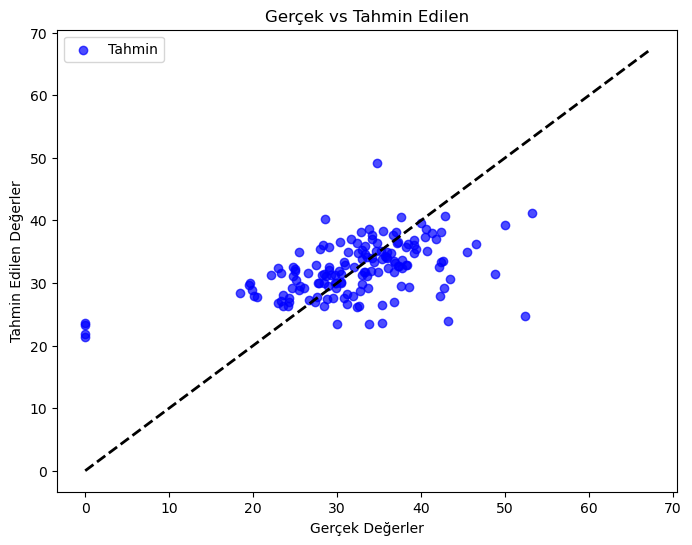


Confusion Matrix:
[[  4  19]
 [  5 126]]

Classification Report:
              precision    recall  f1-score   support

           0       0.44      0.17      0.25        23
           1       0.87      0.96      0.91       131

    accuracy                           0.84       154
   macro avg       0.66      0.57      0.58       154
weighted avg       0.81      0.84      0.81       154

Accuracy: 0.84


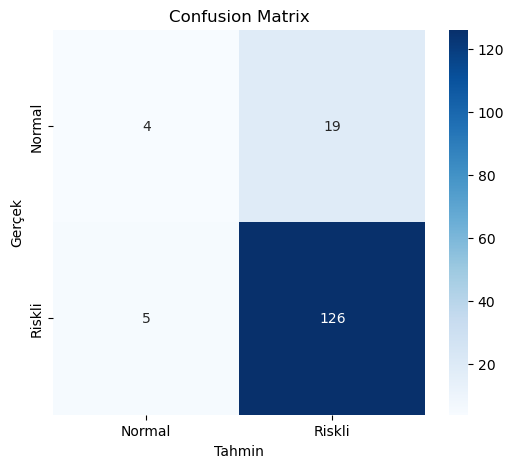


Model başarıyla kaydedildi: regression_model.pkl

Test sonuçları 'predicted_bmi_results.csv' dosyasına kaydedildi.


In [258]:
##%%
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_squared_error, r2_score,
    confusion_matrix, classification_report, accuracy_score
)
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

df = pd.read_csv('diabetes_temizlenmis_ve_normalize_edilmis.csv')


X = df[[
    "Age", "Glucose", "Insulin", "Pregnancies",
    "SkinThickness", "DiabetesPedigreeFunction", "BloodPressure"
]]
y = df["BMI"]


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,   
    random_state=42
)


regressor = LinearRegression()
regressor.fit(X_train, y_train)

y_pred = regressor.predict(X_test)


mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Regresyon Sonuçları:")
print(f"Mean Squared Error: {mse:.2f}")
print(f"R² Score: {r2:.2f}")


plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.7, color='b', label="Tahmin")
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=2)
plt.xlabel("Gerçek Değerler")
plt.ylabel("Tahmin Edilen Değerler")
plt.title("Gerçek vs Tahmin Edilen")
plt.legend()
plt.show()

def bmi_to_class(val):
    return 1 if val >= 25 else 0   # 1 = Riskli, 0 = Normal

y_test_class = y_test.apply(bmi_to_class)
y_pred_class = pd.Series(y_pred).apply(bmi_to_class)


cm = confusion_matrix(y_test_class, y_pred_class)

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_test_class, y_pred_class))

accuracy = accuracy_score(y_test_class, y_pred_class)
print(f"Accuracy: {accuracy:.2f}")

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Riskli"],
    yticklabels=["Normal", "Riskli"]
)
plt.title("Confusion Matrix")
plt.xlabel("Tahmin")
plt.ylabel("Gerçek")
plt.show()


joblib.dump(regressor, "regression_model.pkl")
print("\nModel başarıyla kaydedildi: regression_model.pkl")


results = X_test.copy()
results["Real_BMI"] = y_test.values
results["Predicted_BMI"] = y_pred
results["BMI_Class"] = results["Predicted_BMI"].apply(bmi_to_class)

results.to_csv("predicted_bmi_results.csv", index=False)
print("\nTest sonuçları 'predicted_bmi_results.csv' dosyasına kaydedildi.")


In [168]:
#---------------------------------------------------------------------

C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


Kümelere göre diyabet oranları (Outcome ortalaması):
Cluster
0    0.684466
1    0.130435
2    0.318182
Name: Outcome, dtype: float64


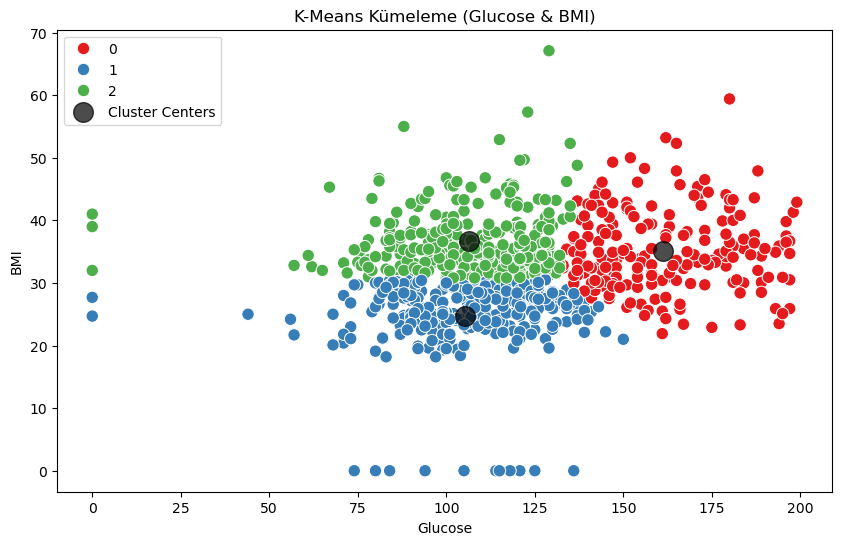

Model başarıyla kaydedildi: classification_model.pkl
Model başarıyla yüklendi.


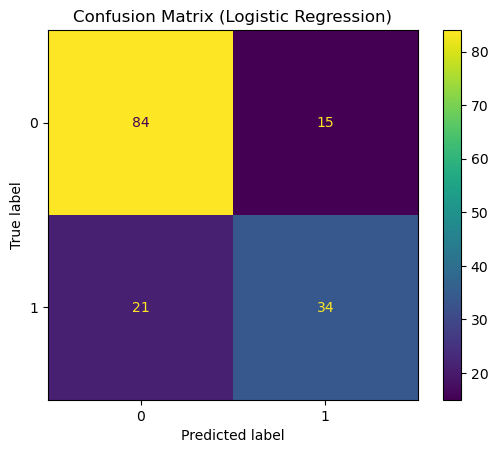

Yüklenen Modelin Accuracy Değeri: 0.7662337662337663


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,ID,Ad,Soyad,Glucose Normalized,BloodPressure Normalized,SkinThickness Normalized,Insulin Normalized,BMI Normalized,DiabetesPedigreeFunction Normalized,Age Normalized,Cluster
0,6,148.0,72.0,35,0.0,33.6,0.627,50,1.0,0,Buse,Kaya,0.743719,0.590164,0.353535,0.000000,0.500745,0.234415,0.483333,0
1,1,85.0,66.0,29,0.0,26.6,0.351,31,0.0,1,Gamze,Yılmaz,0.427136,0.540984,0.292929,0.000000,0.396423,0.116567,0.166667,1
2,8,183.0,64.0,0,0.0,23.3,0.672,32,1.0,2,Sema,Şahin,0.919598,0.524590,0.000000,0.000000,0.347243,0.253629,0.183333,0
3,1,89.0,66.0,23,94.0,28.1,0.167,21,0.0,3,Duygu,Demir,0.447236,0.540984,0.232323,0.111111,0.418778,0.038002,0.000000,1
4,0,137.0,40.0,35,168.0,43.1,2.288,33,1.0,4,Zeynep,Çelik,0.688442,0.327869,0.353535,0.198582,0.642325,0.943638,0.200000,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
763,10,101.0,76.0,48,180.0,32.9,0.171,63,0.0,763,Selin,Aksakal,0.507538,0.622951,0.484848,0.212766,0.490313,0.039710,0.700000,2
764,2,122.0,70.0,27,0.0,36.8,0.340,27,0.0,764,Sude,Keskin,0.613065,0.573770,0.272727,0.000000,0.548435,0.111870,0.100000,2
765,5,121.0,72.0,23,112.0,26.2,0.245,30,0.0,765,Zeynep,Turan,0.608040,0.590164,0.232323,0.132388,0.390462,0.071307,0.150000,1
766,1,126.0,60.0,0,0.0,30.1,0.349,47,1.0,766,Şeyma,Özcan,0.633166,0.491803,0.000000,0.000000,0.448584,0.115713,0.433333,1


In [248]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score

data = pd.read_csv('diabetes_temizlenmis_ve_normalize_edilmis.csv')
X = data[["Glucose", "BMI"]]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(n_clusters=3, random_state=42)
clusters = kmeans.fit_predict(X_scaled)

data["Cluster"] = clusters

print("Kümelere göre diyabet oranları (Outcome ortalaması):")
print(data.groupby("Cluster")["Outcome"].mean())

centers = kmeans.cluster_centers_

centers_original = scaler.inverse_transform(centers)

plt.figure(figsize=(10,6))
sns.scatterplot(
    x=data["Glucose"],
    y=data["BMI"],
    hue=data["Cluster"],
    palette="Set1",
    s=80
)

plt.scatter(
    centers_original[:, 0],
    centers_original[:, 1],
    c="black",
    s=200,
    alpha=0.7,
    label="Cluster Centers"
)

plt.title("K-Means Kümeleme (Glucose & BMI)")
plt.xlabel("Glucose")
plt.ylabel("BMI")
plt.legend()
plt.show()

X = data[["Glucose", "BMI"]]      
y = data["Outcome"] 

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

model = LogisticRegression()
model.fit(X_train, y_train)

joblib.dump(model, "classification_model.pkl")
print("Model başarıyla kaydedildi: classification_model.pkl")

loaded_model = joblib.load("classification_model.pkl")
print("Model başarıyla yüklendi.")

y_pred_loaded = loaded_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred_loaded)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title("Confusion Matrix (Logistic Regression)")
plt.show()

accuracy = accuracy_score(y_test, y_pred_loaded)
print("Yüklenen Modelin Accuracy Değeri:", accuracy)

pd.set_option('display.max_rows', 10)
data

In [173]:
#-------------------------------------------------------------------


--- Makine Öğrenmesi (Sınıflandırma) Adımları ---
Eğitim Seti Boyutu (X_train): (614, 8)
Test Seti Boyutu (X_test): (154, 8)

Confusion Matrix:
[[84 16]
 [27 27]]


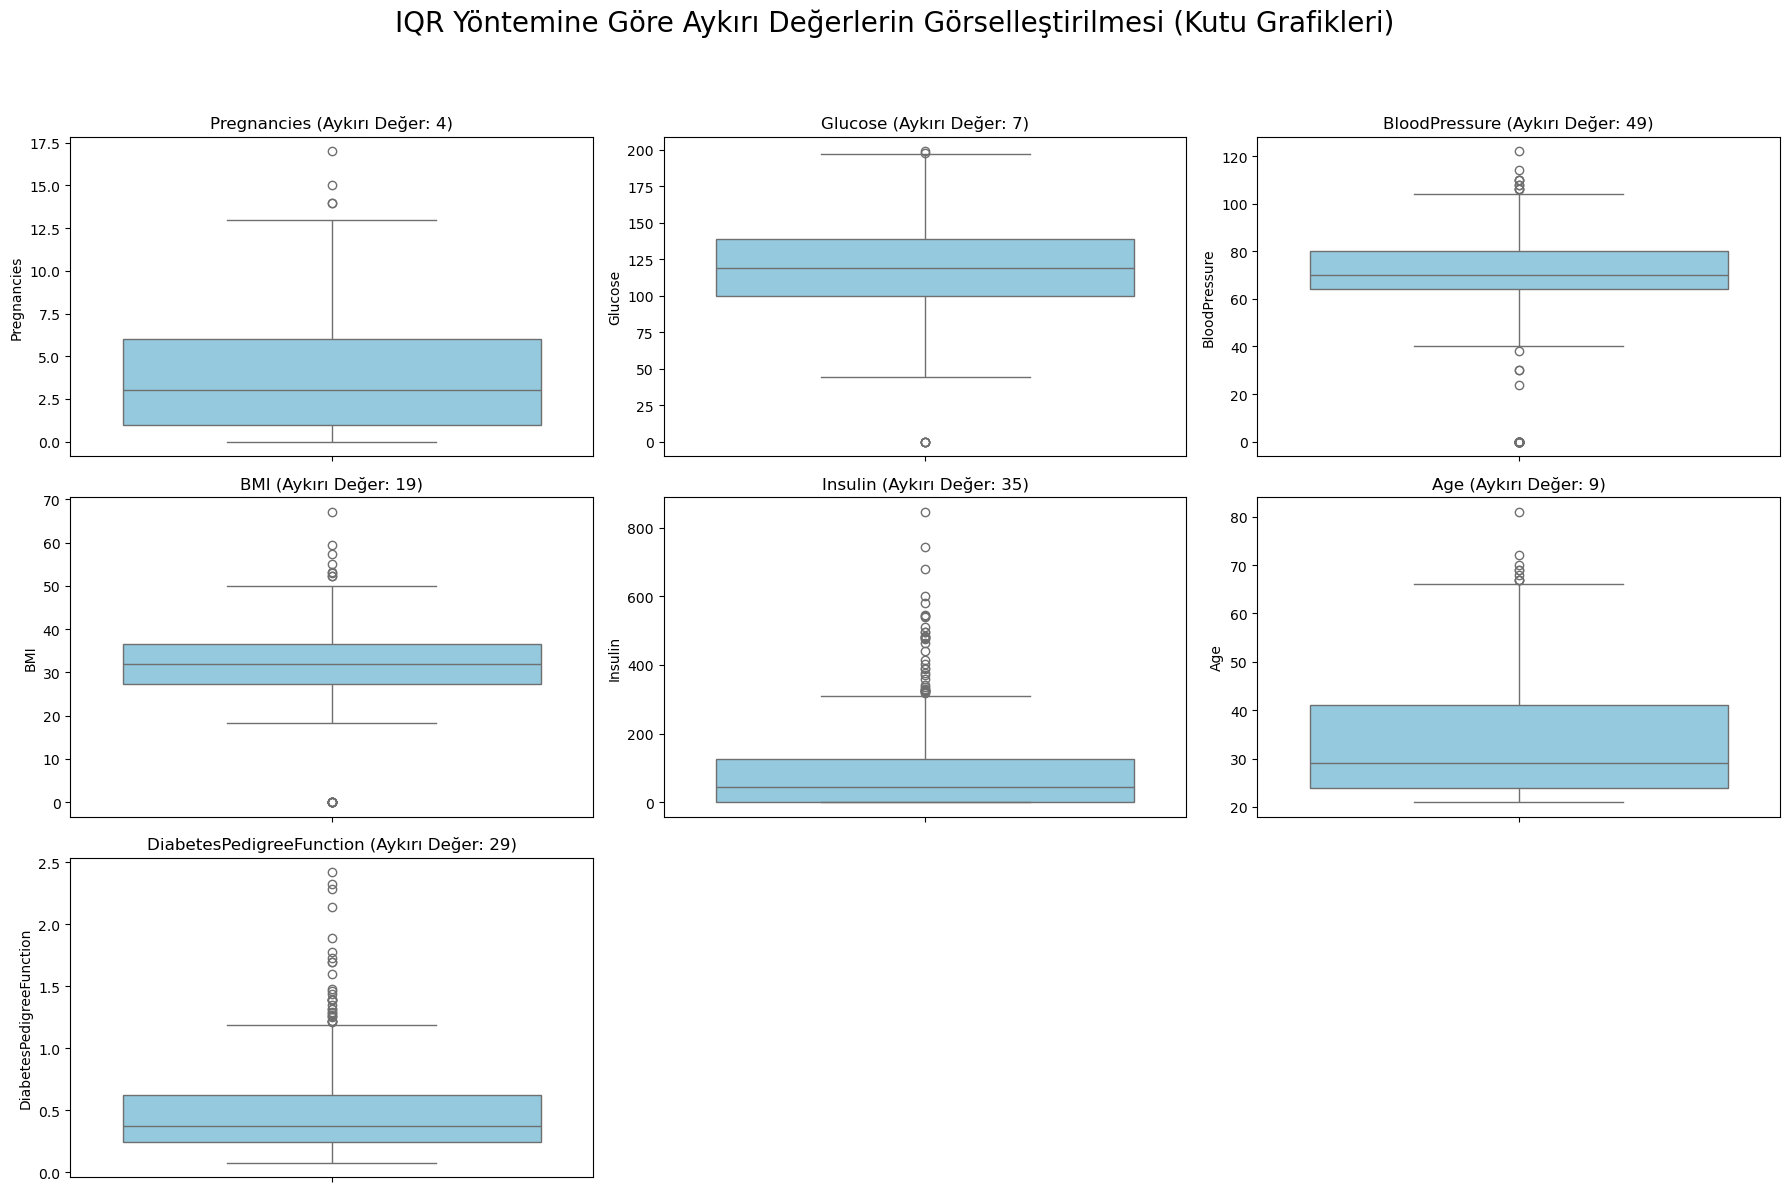

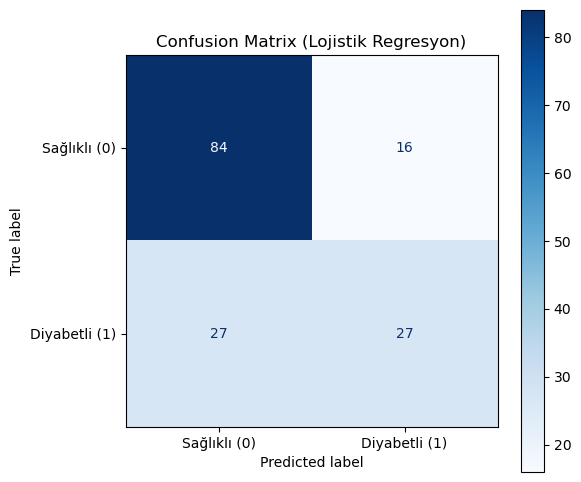


Modelin Doğruluk (Accuracy) Değeri: 0.7208


In [224]:
import pandas as pd
import numpy as np


from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('diabetes_temizlenmis_ve_normalize_edilmis.csv')
outliers_iqr = {}
for col in df.columns:
    if df[col].dtype != 'object':
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        outliers_iqr[col] = df[(df[col] < lower) | (df[col] > upper)][col].count()
outliers_zscore = {}
df_zscore = df.copy()
for col in df_zscore.columns:
    if df_zscore[col].dtype != 'object':
        df_zscore[col+'_ZScore'] = (df_zscore[col] - df_zscore[col].mean()) / df_zscore[col].std()
        outliers_zscore[col] = df_zscore[abs(df_zscore[col+'_ZScore']) > 3][col].count()

cols_to_plot = ['Pregnancies', 'Glucose', 'BloodPressure', 'BMI', 'Insulin', 'Age', 'DiabetesPedigreeFunction']
plt.figure(figsize=(18, 12))
plt.suptitle('IQR Yöntemine Göre Aykırı Değerlerin Görselleştirilmesi (Kutu Grafikleri)', fontsize=20, y=1.02)
for i, col in enumerate(cols_to_plot):
    plt.subplot(3, 3, i + 1)
    sns.boxplot(y=df[col], color='skyblue')
    outlier_count = outliers_iqr.get(col, 0)
    plt.title(f'{col} (Aykırı Değer: {outlier_count})', fontsize=12)
plt.tight_layout(rect=[0, 0.03, 1, 0.98])

print("\n--- Makine Öğrenmesi (Sınıflandırma) Adımları ---")

X = df[['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']]
y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y 
)
print(f"Eğitim Seti Boyutu (X_train): {X_train.shape}")
print(f"Test Seti Boyutu (X_test): {X_test.shape}")

model = LogisticRegression(max_iter=500)
model.fit(X_train, y_train) 

y_pred = model.predict(X_test) 


cm = confusion_matrix(y_test, y_pred) 

print("\nConfusion Matrix:")
print(cm)


plt.figure(figsize=(6, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Sağlıklı (0)', 'Diyabetli (1)'])
disp.plot(cmap=plt.cm.Blues, ax=plt.gca())
plt.title("Confusion Matrix (Lojistik Regresyon)")
plt.show()


accuracy = accuracy_score(y_test, y_pred)
print(f"\nModelin Doğruluk (Accuracy) Değeri: {accuracy:.4f}")


plt.show()

In [176]:
#------------------------------------------------------------------------------

In [179]:
!pip install pgmpy

In [226]:
import pandas as pd
from pgmpy.estimators import TreeSearch
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import MaximumLikelihoodEstimator
from pgmpy.inference import VariableElimination
import matplotlib.pyplot as plt
import networkx as nx

In [250]:
data = pd.read_csv('diabetes_temizlenmis_ve_normalize_edilmis.csv')
data.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,ID,Ad,Soyad,Glucose Normalized,BloodPressure Normalized,SkinThickness Normalized,Insulin Normalized,BMI Normalized,DiabetesPedigreeFunction Normalized,Age Normalized
0,6,148.0,72.0,35,0.0,33.6,0.627,50,1.0,0,Buse,Kaya,0.743719,0.590164,0.353535,0.000000,0.500745,0.234415,0.483333
1,1,85.0,66.0,29,0.0,26.6,0.351,31,0.0,1,Gamze,Yılmaz,0.427136,0.540984,0.292929,0.000000,0.396423,0.116567,0.166667
2,8,183.0,64.0,0,0.0,23.3,0.672,32,1.0,2,Sema,Şahin,0.919598,0.524590,0.000000,0.000000,0.347243,0.253629,0.183333
3,1,89.0,66.0,23,94.0,28.1,0.167,21,0.0,3,Duygu,Demir,0.447236,0.540984,0.232323,0.111111,0.418778,0.038002,0.000000
4,0,137.0,40.0,35,168.0,43.1,2.288,33,1.0,4,Zeynep,Çelik,0.688442,0.327869,0.353535,0.198582,0.642325,0.943638,0.200000


In [252]:
ts = TreeSearch(data, root_node="Glucose")   
best_model = ts.estimate(estimator_type="tan", class_node="Outcome")

INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'Pregnancies': 'N', 'Glucose': 'N', 'BloodPressure': 'N', 'SkinThickness': 'N', 'Insulin': 'N', 'BMI': 'N', 'DiabetesPedigreeFunction': 'N', 'Age': 'N', 'Outcome': 'N', 'ID': 'N', 'Ad': 'C', 'Soyad': 'C', 'Glucose Normalized': 'N', 'BloodPressure Normalized': 'N', 'SkinThickness Normalized': 'N', 'Insulin Normalized': 'N', 'BMI Normalized': 'N', 'DiabetesPedigreeFunction Normalized': 'N', 'Age Normalized': 'N'}


Building tree:   0%|          | 0/171.0 [00:00<?, ?it/s]

Öğrenilen yapı: [('Glucose', 'Glucose Normalized'), ('Glucose', 'ID'), ('ID', 'DiabetesPedigreeFunction'), ('ID', 'BMI'), ('ID', 'Soyad'), ('ID', 'Ad'), ('ID', 'Age'), ('ID', 'BloodPressure'), ('ID', 'SkinThickness'), ('ID', 'SkinThickness Normalized'), ('ID', 'Insulin Normalized'), ('ID', 'Pregnancies'), ('DiabetesPedigreeFunction', 'DiabetesPedigreeFunction Normalized'), ('BMI', 'BMI Normalized'), ('Age', 'Age Normalized'), ('BloodPressure', 'BloodPressure Normalized'), ('Insulin Normalized', 'Insulin'), ('Outcome', 'Pregnancies'), ('Outcome', 'Glucose'), ('Outcome', 'BloodPressure'), ('Outcome', 'SkinThickness'), ('Outcome', 'Insulin'), ('Outcome', 'BMI'), ('Outcome', 'DiabetesPedigreeFunction'), ('Outcome', 'Age'), ('Outcome', 'ID'), ('Outcome', 'Ad'), ('Outcome', 'Soyad'), ('Outcome', 'Glucose Normalized'), ('Outcome', 'BloodPressure Normalized'), ('Outcome', 'SkinThickness Normalized'), ('Outcome', 'Insulin Normalized'), ('Outcome', 'BMI Normalized'), ('Outcome', 'DiabetesPedigre

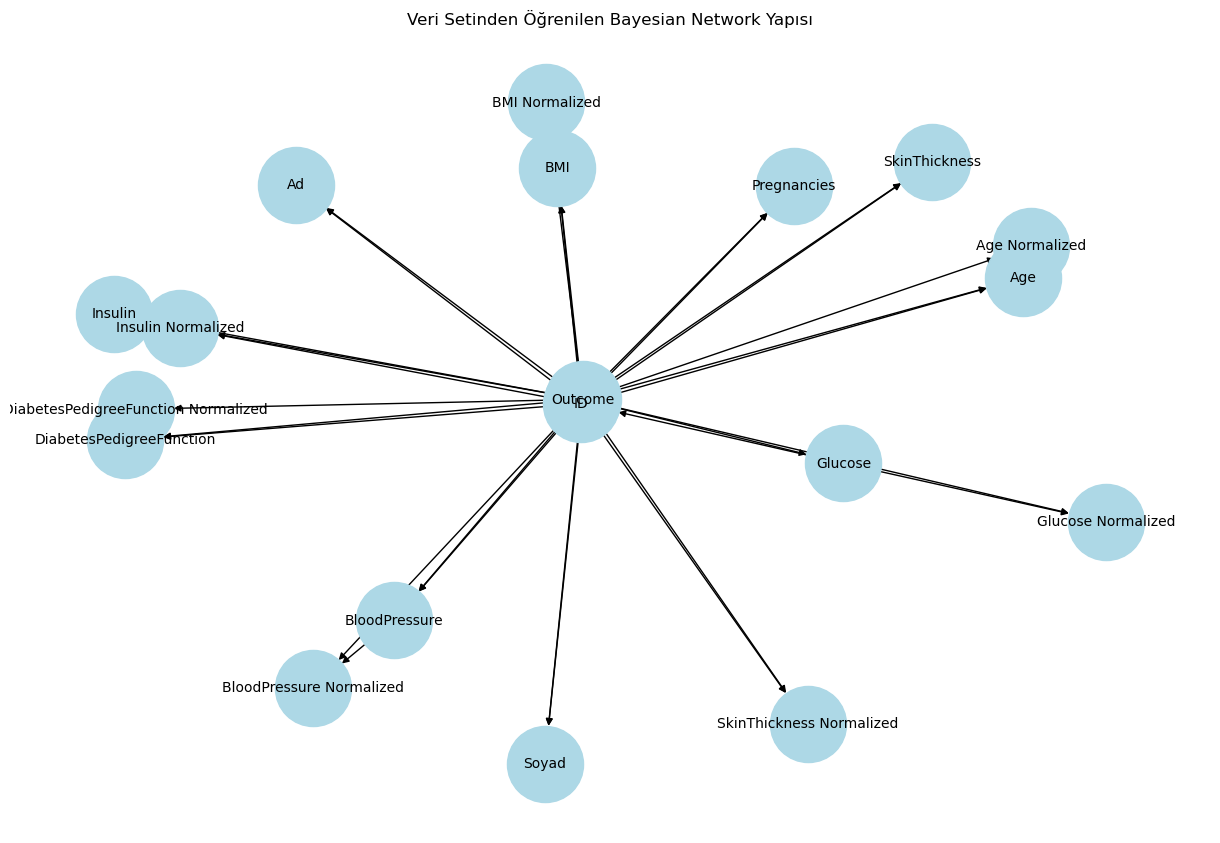

In [253]:
print("Öğrenilen yapı:", best_model.edges())

nx_graph = nx.DiGraph()
nx_graph.add_edges_from(best_model.edges())

plt.figure(figsize=(12, 8))
nx.draw(nx_graph, with_labels=True, node_size=3000, node_color='lightblue', font_size=10)
plt.title("Veri Setinden Öğrenilen Bayesian Network Yapısı")
plt.show()

In [234]:
model = DiscreteBayesianNetwork(best_model.edges())
model.fit(data, estimator=MaximumLikelihoodEstimator)

INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'Pregnancies': 'N', 'Glucose': 'N', 'BloodPressure': 'N', 'SkinThickness': 'N', 'Insulin': 'N', 'BMI': 'N', 'DiabetesPedigreeFunction': 'N', 'Age': 'N', 'Outcome': 'N', 'ID': 'N', 'Ad': 'C', 'Soyad': 'C', 'Glucose Normalized': 'N', 'BloodPressure Normalized': 'N', 'SkinThickness Normalized': 'N', 'Insulin Normalized': 'N', 'BMI Normalized': 'N', 'DiabetesPedigreeFunction Normalized': 'N', 'Age Normalized': 'N'}


In [236]:
inference = VariableElimination(model)

In [238]:
q1 = inference.query(
    variables=['Outcome'],
    evidence={'Glucose': data['Glucose'].quantile(0.80)}
)
print("Glucose yüksek olduğunda diyabet olasılığı:\n", q1)

Glucose yüksek olduğunda diyabet olasılığı:
 +--------------+----------------+
| Outcome      |   phi(Outcome) |
+==============+================+
| Outcome(0.0) |         0.4444 |
+--------------+----------------+
| Outcome(1.0) |         0.5556 |
+--------------+----------------+


In [240]:
q2 = inference.query(
    variables=['Outcome'],
    evidence={'BMI': data['BMI'].quantile(0.75)}
)

print("BMI yüksek olduğunda diyabet olasılığı:\n", q2)

BMI yüksek olduğunda diyabet olasılığı:
 +--------------+----------------+
| Outcome      |   phi(Outcome) |
+==============+================+
| Outcome(0.0) |         0.4000 |
+--------------+----------------+
| Outcome(1.0) |         0.6000 |
+--------------+----------------+


In [256]:
q3 = inference.query(
    variables=['Age'],
    evidence={'BMI': data['BMI'].quantile(0.80)}
)

print("BMI yüksek olduğunda Age değerinin olasılık dağılımı:\n", q3)

BMI yüksek olduğunda Age değerinin olasılık dağılımı:
 +---------+------------+
| Age     |   phi(Age) |
+=========+============+
| Age(21) |     0.0000 |
+---------+------------+
| Age(22) |     0.3333 |
+---------+------------+
| Age(23) |     0.0000 |
+---------+------------+
| Age(24) |     0.3333 |
+---------+------------+
| Age(25) |     0.0000 |
+---------+------------+
| Age(26) |     0.0000 |
+---------+------------+
| Age(27) |     0.0000 |
+---------+------------+
| Age(28) |     0.0000 |
+---------+------------+
| Age(29) |     0.0000 |
+---------+------------+
| Age(30) |     0.0000 |
+---------+------------+
| Age(31) |     0.0000 |
+---------+------------+
| Age(32) |     0.0000 |
+---------+------------+
| Age(33) |     0.0000 |
+---------+------------+
| Age(34) |     0.0000 |
+---------+------------+
| Age(35) |     0.0000 |
+---------+------------+
| Age(36) |     0.0000 |
+---------+------------+
| Age(37) |     0.0000 |
+---------+------------+
| Age(38) |     0.00